In [1]:
from google.colab import drive
drive.mount('/content/drive')

import sys
sys.path.append('/content/drive/MyDrive/PFT - IA aplicado a Imágenes Médicas/Colabs_Ingeniería/Desde cero')

from preparar_datos import preparar_datos_mnist_binario, calcular_metricas

Mounted at /content/drive


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Info del split: {'n_train': 9776, 'n_val': 2095, 'n_test': 2095, 'clase_0': 3, 'clase_1': 8, 'semilla': 42}
X_train: (9776, 784)  y_train: (9776,)
X_val:   (2095, 784)  y_val:   (2095,)
X_test:  (2095, 784)  y_test:  (2095,)
Early stopping en época 18 (val no mejora hace 10 épocas)


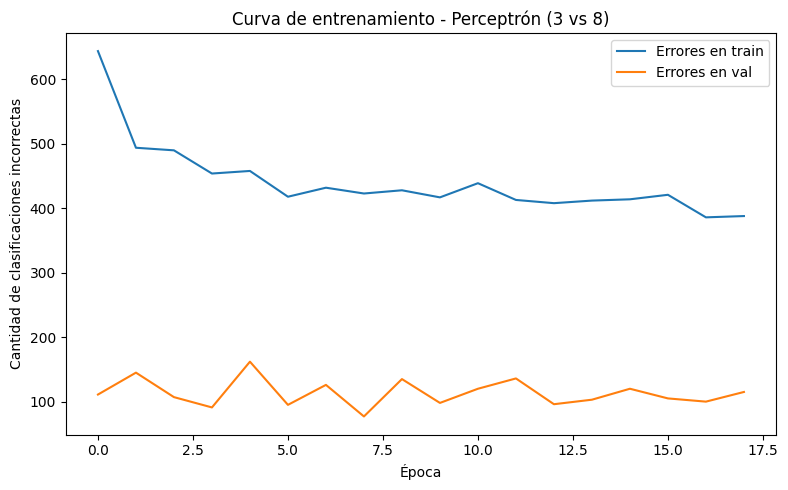


=== Resultados en TEST (Perceptrón, 3 vs 8) ===
accuracy       : 0.9609
sensibilidad   : 0.9551
especificidad  : 0.9664
f1             : 0.9598
auc            : 0.9892


In [2]:
"""
Perceptrón desde cero - Clasificación binaria 3 vs 8
========================================================================
Etapa de validación conceptual - usa el módulo común preparar_datos.py
"""

import numpy as np
import matplotlib.pyplot as plt

from preparar_datos import preparar_datos_mnist_binario, calcular_metricas, SEMILLA

# =========================================================
# 0. SEMILLA
# =========================================================
np.random.seed(SEMILLA)

# =========================================================
# 1. DATOS -- mismo bloque que usan la MLP y la CNN
#    (etiquetas -1/1 porque así trabaja el Perceptrón clásico)
# =========================================================
datos = preparar_datos_mnist_binario(formato='vector', etiquetas=(-1, 1))
X_train, y_train = datos['train']
X_val, y_val = datos['val']
X_test, y_test = datos['test']

# el Perceptrón espera vectores 1D de etiquetas, no columna (N,1)
y_train = y_train.flatten()
y_val = y_val.flatten()
y_test = y_test.flatten()

print("Info del split:", datos['info'])
print("X_train:", X_train.shape, " y_train:", y_train.shape)
print("X_val:  ", X_val.shape, " y_val:  ", y_val.shape)
print("X_test: ", X_test.shape, " y_test: ", y_test.shape)


# =========================================================
# 2. CLASE PERCEPTRON -- misma lógica que tenías, + validación
# =========================================================
class Perceptron():
    def __init__(self, eta=0.01, n_iter=10, paciencia=10):
        self.eta = eta                # tasa de aprendizaje
        self.n_iter = n_iter          # número máximo de épocas
        self.paciencia = paciencia    # épocas sin mejorar en val antes de frenar

    def suma_ponderada(self, X):
        return np.dot(X, self.w_[1:]) + self.w_[0]

    def predict(self, X):
        return np.where(self.suma_ponderada(X) > 0.0, 1, -1)

    def _errores(self, X, y):
        """Cantidad de clasificaciones incorrectas (para trackear val)."""
        y_pred = self.predict(X)
        return np.sum(y_pred != y)

    def fit(self, X, y, X_val=None, y_val=None):
        self.w_ = np.zeros(1 + X.shape[1])
        self.errors_ = []        # errores en TRAIN por época (como tenías)
        self.val_errors_ = []    # errores en VAL por época (nuevo)

        usar_val = X_val is not None and y_val is not None
        mejor_val_error = np.inf
        contador = 0
        mejor_w = self.w_.copy()

        for epoca in range(self.n_iter):
            error = 0
            for xi, target in zip(X, y):
                y_pred = self.predict(xi)
                update = self.eta * (target - y_pred)
                self.w_[1:] = self.w_[1:] + update * xi
                self.w_[0] = self.w_[0] + update
                error += int(update != 0.0)
            self.errors_.append(error)

            if usar_val:
                val_error = self._errores(X_val, y_val)
                self.val_errors_.append(val_error)

                # early stopping basado en desempeño en VALIDACIÓN
                if val_error < mejor_val_error:
                    mejor_val_error = val_error
                    mejor_w = self.w_.copy()
                    contador = 0
                else:
                    contador += 1

                if contador >= self.paciencia:
                    print(f"Early stopping en época {epoca+1} "
                          f"(val no mejora hace {self.paciencia} épocas)")
                    break

        if usar_val:
            self.w_ = mejor_w  # restaura los pesos de la mejor época en val

        return self


# =========================================================
# 3. ENTRENAMIENTO
# =========================================================
p = Perceptron(eta=0.01, n_iter=200, paciencia=10)
p.fit(X_train, y_train, X_val=X_val, y_val=y_val)

# =========================================================
# 4. CURVA DE ERRORES -- train vs val por época
# =========================================================
plt.figure(figsize=(8, 5))
plt.plot(p.errors_, label='Errores en train')
plt.plot(p.val_errors_, label='Errores en val')
plt.xlabel('Época')
plt.ylabel('Cantidad de clasificaciones incorrectas')
plt.title('Curva de entrenamiento - Perceptrón (3 vs 8)')
plt.legend()
plt.tight_layout()
plt.show()

# =========================================================
# 5. EVALUACIÓN FINAL EN TEST
# =========================================================
y_pred_test = p.predict(X_test)
y_scores_test = p.suma_ponderada(X_test)  # score continuo, para AUC

# calcular_metricas espera 0/1 -> convertimos desde -1/1
y_test_01 = np.where(y_test == 1, 1, 0)
y_pred_test_01 = np.where(y_pred_test == 1, 1, 0)

metricas_test = calcular_metricas(
    y_true=y_test_01,
    y_pred=y_pred_test_01,
    y_scores=y_scores_test,
    clase_positiva=1,
)

print("\n=== Resultados en TEST (Perceptrón, 3 vs 8) ===")
for nombre, valor in metricas_test.items():
    print(f"{nombre:15s}: {valor:.4f}" if valor is not None else f"{nombre:15s}: N/A")

In [3]:
print("Total de imágenes en test:", len(y_test))
print("Imágenes del número 3:", np.sum(y_test == -1))
print("Imágenes del número 8:", np.sum(y_test == 1))

Total de imágenes en test: 2095
Imágenes del número 3: 1071
Imágenes del número 8: 1024
